In [1]:
import os
import json
from dotenv import load_dotenv
from openai import OpenAI
import gradio as gr

# Initialization

load_dotenv(override=True)

openai_api_key = os.getenv('OPENAI_API_KEY')
if openai_api_key:
    print(f"OpenAI API Key exists and begins {openai_api_key[:8]}")
else:
    print("OpenAI API Key not set")
    
MODEL = "gpt-6-luna"
openai = OpenAI()

OpenAI API Key exists and begins sk-proj-


In [2]:
system_message = """
You are a helpful assistant for an Airline called FlightAI.
Give short, courteous answers, no more than 1 sentence.
Always be accurate. If you don't know the answer, say so.
"""

In [ ]:
def chat(message, history):
    history = [{"role":h["role"], "content":h["content"]} for h in history]
    messages = [{"role": "system", "content": system_message}] + history + [{"role": "user", "content": message}]
    response = openai.chat.completions.create(model=MODEL, reasoning_effort="none", messages=messages)
    return response.choices[0].message.content

gr.ChatInterface(fn=chat, type="messages").launch()

In [ ]:
#
#
#############  TOOLS EXAMPE
#
# 1. define a function
#

ticket_prices = {"london": "$799", "paris": "$899", "tokyo": "$1400", "berlin": "$499"}
def get_ticket_price(dst:str)->str:
    print(f"Tool called for city {dst}")
    price = ticket_prices.get(dst.lower(), "Unknown ticket price")
    return f"The price of a ticket to {dst} is {price}"
#
#
# 2. create a dictionary that describe the tools (fixed format)
#
price_function = {
    "name": "get_ticket_price",
    "description": "Get the price of a return ticket to the destination city.",
    "parameters": {
        "type": "object",
        "properties": {
            "dst": {
                "type": "string",
                "description": "The city that the customer wants to travel to",
            },
        },
        "required": ["dst"],
        "additionalProperties": False
    }
}

#
#
# 3. define the list of tools to send to the LLM
#
tools = [{"type": "function", "function": price_function}]


In [ ]:
#
# 4. send the message with the history and list of tools and detect if we get back
#    a request to use a tool or not
#
def chat(message, history):
    history = [{"role":h["role"], "content":h["content"]} for h in history]
    messages = [{"role": "system", "content": system_message}] + history + [{"role": "user", "content": message}]
    response = openai.chat.completions.create(model=MODEL, reasoning_effort="none", messages=messages, tools=tools)

    while response.choices[0].finish_reason=="tool_calls":
        message = response.choices[0].message
        response = handle_tool_calls(message)
        messages.append(message)
        messages.append(response)
        response = openai.chat.completions.create(model=MODEL, reasoning_effort="none", messages=messages)
    
    return response.choices[0].message.content

In [6]:
#
# 3/4. The function to call the tool
#      of course this should be available in the function above.. but we put it here
# 
#   Here is not a super smart way to call a function.. matching the name using if..
#   you just probably reference the function and send the parameters in one go (no if..)  
def handle_tool_calls(message):
    responses = []
    #
    # note that we loop through the tool calls that the LLm wants to call
    for tool_call in message.tool_calls:
        if tool_call.function.name == "get_ticket_price":
            arguments = json.loads(tool_call.function.arguments)
            city = arguments.get('destination_city')
            price_details = get_ticket_price(city)
            responses.append({
                "role": "tool",
                "content": price_details,
                "tool_call_id": tool_call.id
            })
    return responses

In [ ]:
#############################################
##
##
##     DAY 5 - AGENTS
##
##
#############################################
##
##
## WE are going to add a few things to the Airline assistant

In [5]:
# imports, ENV and DB setup
import os
import json
from dotenv import load_dotenv
from openai import OpenAI
import gradio as gr
import sqlite3

load_dotenv(override=True)

openai_api_key = os.getenv('OPENAI_API_KEY')
if openai_api_key:
    print(f"OpenAI API Key exists and begins {openai_api_key[:8]}")
else:
    print("OpenAI API Key not set")
    
MODEL = "gpt-6-luna"
openai = OpenAI()

#
# we also setup the DB again
DB = "prices.db"

with sqlite3.connect(DB) as conn:
    cursor = conn.cursor()
    cursor.execute('CREATE TABLE IF NOT EXISTS prices (city TEXT PRIMARY KEY, price REAL)')
    conn.commit()

def set_ticket_price(city, price):
    with sqlite3.connect(DB) as conn:
        cursor = conn.cursor()
        cursor.execute('INSERT INTO prices (city, price) VALUES (?, ?) ON CONFLICT(city) DO UPDATE SET price = ?', (city.lower(), price, price))
        conn.commit()

ticket_prices = {"london":799, "paris": 899, "tokyo": 1420, "sydney": 2999}
for city, price in ticket_prices.items():
    set_ticket_price(city, price)   

def get_ticket_price(city):
    print(f"DATABASE TOOL CALLED: Getting price for {city}", flush=True)
    with sqlite3.connect(DB) as conn:
        cursor = conn.cursor()
        cursor.execute('SELECT price FROM prices WHERE city = ?', (city.lower(),))
        result = cursor.fetchone()
        return f"Ticket price to {city} is ${result[0]}" if result else "No price data available for this city"
    
get_ticket_price("Tokyo")             

OpenAI API Key exists and begins sk-proj-
DATABASE TOOL CALLED: Getting price for Tokyo


'Ticket price to Tokyo is $1420.0'

In [7]:
#
# HERE WE DEFINE AGAIN THE TOOL (as json blob)
# 
price_function = {
    "name": "get_ticket_price",
    "description": "Get the price of a return ticket to the destination city.",
    "parameters": {
        "type": "object",
        "properties": {
            "destination_city": {
                "type": "string",
                "description": "The city that the customer wants to travel to",
            },
        },
        "required": ["destination_city"],
        "additionalProperties": False
    }
}
tools = [{"type": "function", "function": price_function}]
tools

[{'type': 'function',
  'function': {'name': 'get_ticket_price',
   'description': 'Get the price of a return ticket to the destination city.',
   'parameters': {'type': 'object',
    'properties': {'destination_city': {'type': 'string',
      'description': 'The city that the customer wants to travel to'}},
    'required': ['destination_city'],
    'additionalProperties': False}}}]

In [8]:
#
# HERE WE DEFINE:
# - THE CHAT FUNCTION (THE VERSION THAT CAN HANDLE TOOLS)
# - THR FUNCTION THAT HANDLES THE TOOL
# - THE SYSTEM MESSAGE
def handle_tool_calls(message):
    responses = []
    for tool_call in message.tool_calls:
        if tool_call.function.name == "get_ticket_price":
            arguments = json.loads(tool_call.function.arguments)
            city = arguments.get('destination_city')
            price_details = get_ticket_price(city)
            responses.append({
                "role": "tool",
                "content": price_details,
                "tool_call_id": tool_call.id
            })
    return responses


def chat(message, history):
    history = [{"role":h["role"], "content":h["content"]} for h in history]
    messages = [{"role": "system", "content": system_message}] + history + [{"role": "user", "content": message}]
    response = openai.chat.completions.create(model=MODEL, reasoning_effort="none", messages=messages, tools=tools)

    while response.choices[0].finish_reason=="tool_calls":
        message = response.choices[0].message
        responses = handle_tool_calls(message)
        messages.append(message)
        messages.extend(responses)
        response = openai.chat.completions.create(model=MODEL, reasoning_effort="none", messages=messages, tools=tools)
    
    return response.choices[0].message.content

system_message = """
You are a helpful assistant for an Airline called FlightAI.
Give short, courteous answers, no more than 1 sentence.
Always be accurate. If you don't know the answer, say so.
"""

In [ ]:
#
# HERE we launche Gradio chat (note that we listen on all interfaces)
gr.ChatInterface(fn=chat, type="messages").launch(server_name="0.0.0.0")

* Running on local URL:  http://0.0.0.0:7860
* To create a public link, set `share=True` in `launch()`.


DATABASE TOOL CALLED: Getting price for London
DATABASE TOOL CALLED: Getting price for Bologna


In [18]:
################################
##
##
## LET's NOW BUILD AN IMAGE
##
##
################################
##
# Some imports for handling images

import base64
from io import BytesIO
from PIL import Image

def artist(city):
    image_response = openai.images.generate(
            model="gpt-image-1-mini",
            prompt=f"An image representing a vacation in {city}, showing tourist spots and everything unique about {city}, in a vibrant pop-art style with a slight homoerotic innuendo",
            size="1024x1024",
            n=1,
        )
    image_base64 = image_response.data[0].b64_json
    image_data = base64.b64decode(image_base64)
    return Image.open(BytesIO(image_data))

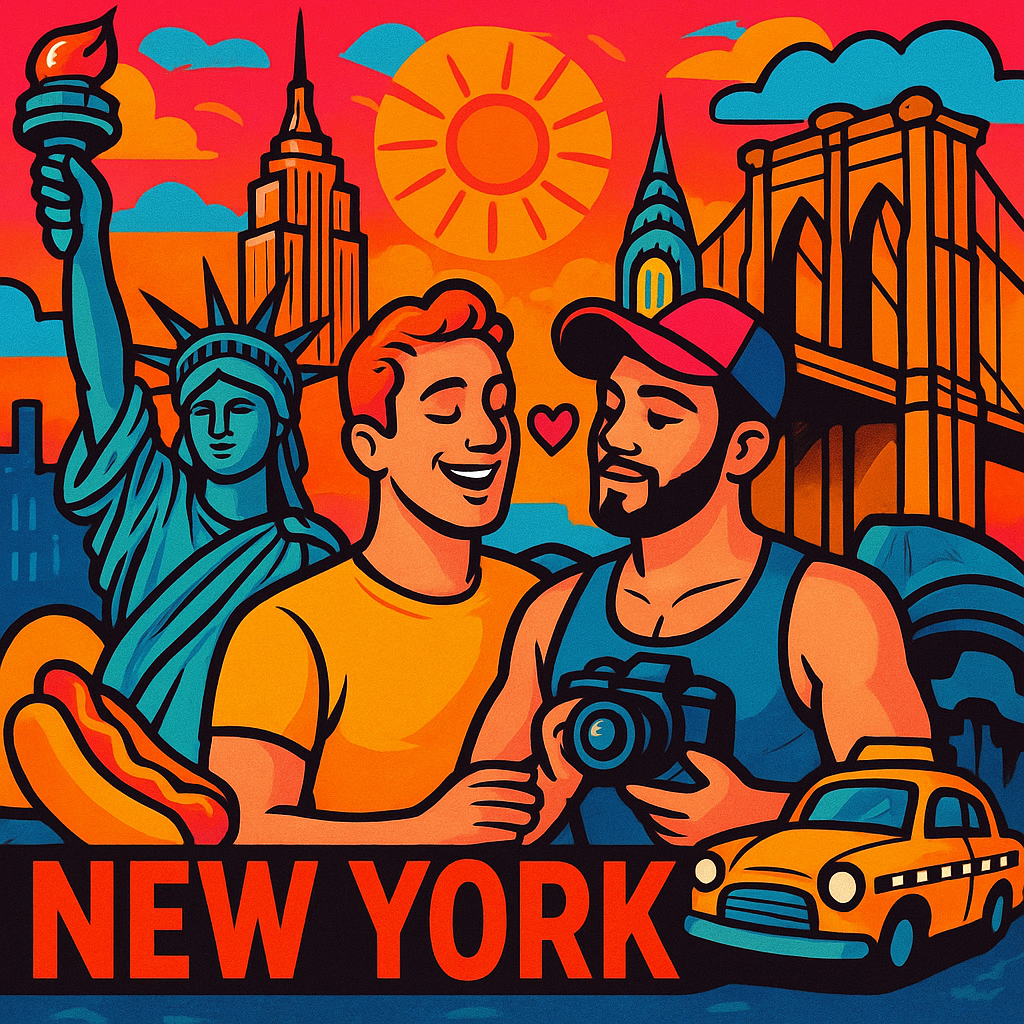

In [19]:
# HERE WE DISPLAY IT AS AN EXAMPLE
image = artist("New York City")
display(image)

In [20]:
#
#
# THIS IS FOR TEXT TO SPEACH
def talker(message):
    response = openai.audio.speech.create(
      model="gpt-4o-mini-tts",
      voice="onyx",    # Also, try replacing onyx with alloy or coral
      input=message
    )
    return response.content

In [22]:
#
#  NOW WE PUT CHAT, IMAGE AND VOICE CREATION ALL TOGETHER
#  - THE CHAT FUNCTION: this does not change much but now:
#        - we only get history as input (this will include the new message)
#        - we have a var for a list of cities (starts as []), an image(None) and voice content   
#        - we call a slightly different function to handle the tools
#
# - THE HANDLE TOOL FUNCTION: if a tool is called, we collect the name of the destination city and at the end we return also the list of cities
#    
#
def handle_tool_calls_and_return_cities(message):
    responses = []
    cities = []
    for tool_call in message.tool_calls:
        if tool_call.function.name == "get_ticket_price":
            arguments = json.loads(tool_call.function.arguments)
            city = arguments.get('destination_city')
            cities.append(city)
            price_details = get_ticket_price(city)
            responses.append({
                "role": "tool",
                "content": price_details,
                "tool_call_id": tool_call.id
            })
    return responses, cities

def chat(history):
    history = [{"role":h["role"], "content":h["content"]} for h in history]
    messages = [{"role": "system", "content": system_message}] + history
    response = openai.chat.completions.create(model=MODEL, reasoning_effort="none", messages=messages, tools=tools)
    cities = []
    image = None

    while response.choices[0].finish_reason=="tool_calls":
        message = response.choices[0].message
        responses, cities = handle_tool_calls_and_return_cities(message)
        messages.append(message)
        messages.extend(responses)
        response = openai.chat.completions.create(model=MODEL, reasoning_effort="none", messages=messages, tools=tools)

    reply = response.choices[0].message.content
    history += [{"role":"assistant", "content":reply}]

    voice = talker(reply)

    if cities:
        image = artist(cities[0])
    
    return history, voice, image


In [24]:
#
#  GRADIO SETUP
# - first setup the call backs
# - define the UI (context manager style)
# - Map events/components to callbacks

# 1. Callbacks (along with the chat() function above)
def put_message_in_chatbot(message, history):
        # we need this so that the we get both the history and the last message in the same list
        # before it is passed to our real callback function
        return "", history + [{"role":"user", "content":message}]


# 2. UI definition
# we create 3 rows:
#  - chatbot screen on top with an image output
#  - audio output
#  - textbox
with gr.Blocks() as ui:
    with gr.Row():
        chatbot = gr.Chatbot(height=500, type="messages")
        image_output = gr.Image(height=500, interactive=False)
    with gr.Row():
        audio_output = gr.Audio(autoplay=True)
    with gr.Row():
        message = gr.Textbox(label="Chat with our AI Assistant:")


# 3. Hooking up events to callbacks
    # - first: when a message is submitted (3rd row)
    #          the input comes from the elements: message and chatbot
    #          the output goes to: message and chatbot;  
    #          the function gets the history and the message and put them together
    # - second: call the function chat with input chatbot and send the output of the function (history, audio, picture)
    #          also to the elements chatbot, audio_output and image_output
    message.submit(put_message_in_chatbot, 
                   inputs=[message, chatbot], 
                   outputs=[message, chatbot]).then(chat, 
                                                    inputs=chatbot, 
                                                    outputs=[chatbot, audio_output, image_output])
# then we launch it
ui.launch(inbrowser=True, auth=("ed", "bananas"), server_name="0.0.0.0")

/var/folders/gn/kqmw_2pn20v4dptbpqx34zfw0000gn/T/ipykernel_92936/988879161.py:21: DeprecationWarning: The default value of 'allow_tags' in gr.Chatbot will be changed from False to True in Gradio 6.0. You will need to explicitly set allow_tags=False if you want to disable tags in your chatbot.
  chatbot = gr.Chatbot(height=500, type="messages")
ERROR:    [Errno 48] error while attempting to bind on address ('0.0.0.0', 7860): address already in use
ERROR:    [Errno 48] error while attempting to bind on address ('0.0.0.0', 7861): address already in use


* Running on local URL:  http://0.0.0.0:7862
* To create a public link, set `share=True` in `launch()`.


DATABASE TOOL CALLED: Getting price for Bologna
